In [4]:
# ==============================================================================
# BLOQUE 1 - INSTALACION DE DEPENDENCIAS
# ==============================================================================

print("⏳ Instalando dependencias...")

!pip install -q datasets transformers mlflow scikit-learn pandas numpy matplotlib seaborn

print("✅ Dependencias instaladas")

⏳ Instalando dependencias...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 63.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━

In [5]:
# ==============================================================================
# BLOQUE 2 - IMPORTACIONES
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from datasets import load_dataset

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score
)

from sklearn.preprocessing import LabelEncoder

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import mlflow
import mlflow.sklearn

warnings.filterwarnings("ignore")

print("✅ Librerías cargadas")

✅ Librerías cargadas


In [6]:
# ==============================================================================
# BLOQUE 3 - CARGA DEL DATASET
# ==============================================================================

print("📦 Descargando dataset...")

dataset = load_dataset(
    "bitext/Bitext-wealth-management-llm-chatbot-training-dataset",
    split="train"
)

df = pd.DataFrame(dataset)

print("\nPrimeros registros:")
display(df.head())

print("\nForma del dataset:")
print(df.shape)

📦 Descargando dataset...


README.md:   0%|          | 0.00/9.81k [00:00<?, ?B/s]

bitext-wealth-management-llm-chatbot-tra(…): reconstructing file:   0%|          |  0.00B / 25.9MB            

bitext-wealth-management-llm-chatbot-tra(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23806 [00:00<?, ? examples/s]


Primeros registros:


,system_prompt,instruction,intent,category,tags,response
0,You are an expert in costumer support for weal...,i need help to arrange a meeting,arrange_meeting,BECOME_CLIENT,BQ,Sure! I'm here to assist you with arranging a ...
1,You are an expert in costumer support for weal...,need ot set up a meeting with a manager could ...,arrange_meeting,BECOME_CLIENT,BCILPQZ,I'm on it! I'm here to assist you in arranging...
2,You are an expert in costumer support for weal...,"I'd like to set up a meeting with a manager, h...",arrange_meeting,BECOME_CLIENT,BCILP,I'm happy to help! I'm here to assist you in s...
3,You are an expert in costumer support for weal...,wanna set up a meeting with a manager help me,arrange_meeting,BECOME_CLIENT,BCLQ,I'll take care of it! I'm here to assist you i...
4,You are an expert in costumer support for weal...,I would like to arrange a meteing with a manager,arrange_meeting,BECOME_CLIENT,BPZ,Sure! I'm here to assist you in setting up a m...



Forma del dataset:
(23806, 6)


Número de clases:
24

Distribución de clases:


,count
intent,
check_services,1000
portfolio_performance,1000
search_for_stocks,999
become_client,998
customer_service,998
human_agent,998
minimum_amount_to_invest,998
delete_account,997
portfolio_value,997


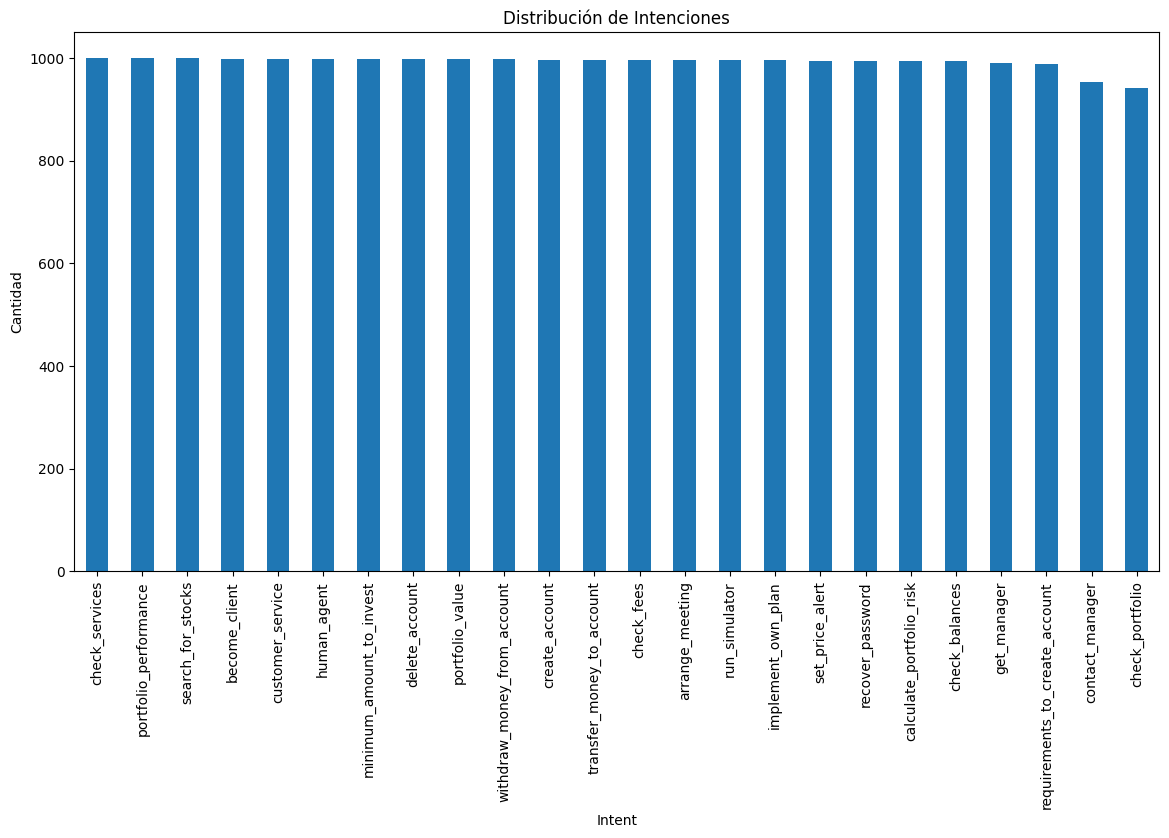

In [7]:
# ==============================================================================
# BLOQUE 4 - EDA
# ==============================================================================

print("Número de clases:")

print(df["intent"].nunique())

print("\nDistribución de clases:")

display(df["intent"].value_counts())

plt.figure(figsize=(14,7))

df["intent"].value_counts().plot(kind="bar")

plt.title("Distribución de Intenciones")

plt.xlabel("Intent")

plt.ylabel("Cantidad")

plt.xticks(rotation=90)

plt.show()

In [8]:
# ==============================================================================
# BLOQUE 5 - LIMPIEZA
# ==============================================================================

print("Registros iniciales:", len(df))

df = df.drop_duplicates()

df = df.dropna()

df["instruction"] = (
    df["instruction"]
    .astype(str)
    .str.lower()
    .str.strip()
)

print("Registros finales:", len(df))

print("✅ Limpieza completada")

Registros iniciales: 23806
Registros finales: 23806
✅ Limpieza completada


In [9]:
# ==============================================================================
# BLOQUE 6 - PREPARACION
# ==============================================================================

X = df["instruction"]

y = df["intent"]

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Train:", len(X_train))
print("Test :", len(X_test))

Train: 19044
Test : 4762


In [10]:
# ==============================================================================
# BLOQUE 7 - LOGISTIC REGRESSION
# ==============================================================================

pipe_lr = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(max_features=5000)
    ),
    (
        "clf",
        LogisticRegression(
            max_iter=2000
        )
    )
])

param_grid_lr = {
    "clf__C":[0.01,0.1,1,10]
}

grid_lr = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid_lr,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_lr.fit(X_train,y_train)

print("Mejores parámetros:")

print(grid_lr.best_params_)

Mejores parámetros:
{'clf__C': 10}


In [11]:
# ==============================================================================
# BLOQUE 8 - EVALUACION LR
# ==============================================================================

pred_lr = grid_lr.predict(X_test)

acc_lr = accuracy_score(y_test,pred_lr)

prec_lr = precision_score(
    y_test,
    pred_lr,
    average="weighted"
)

rec_lr = recall_score(
    y_test,
    pred_lr,
    average="weighted"
)

f1_lr = f1_score(
    y_test,
    pred_lr,
    average="weighted"
)

print("Accuracy :",acc_lr)
print("Precision:",prec_lr)
print("Recall   :",rec_lr)
print("F1       :",f1_lr)

Accuracy : 0.9821503569928601
Precision: 0.9823647117700253
Recall   : 0.9821503569928601
F1       : 0.9822225038707043


In [12]:
# ==============================================================================
# BLOQUE 9 - RANDOM FOREST
# ==============================================================================

pipe_rf = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(max_features=5000)
    ),
    (
        "clf",
        RandomForestClassifier(
            random_state=42
        )
    )
])

param_grid_rf = {

    "clf__n_estimators":[100,200],

    "clf__max_depth":[
        10,
        20,
        None
    ]
}

grid_rf = GridSearchCV(

    estimator=pipe_rf,

    param_grid=param_grid_rf,

    cv=5,

    scoring="f1_weighted",

    n_jobs=-1

)

grid_rf.fit(X_train,y_train)

print(grid_rf.best_params_)

{'clf__max_depth': None, 'clf__n_estimators': 200}


In [13]:
# ==============================================================================
# BLOQUE 10 - EVALUACION RF
# ==============================================================================

pred_rf = grid_rf.predict(X_test)

acc_rf = accuracy_score(y_test,pred_rf)

prec_rf = precision_score(
    y_test,
    pred_rf,
    average="weighted"
)

rec_rf = recall_score(
    y_test,
    pred_rf,
    average="weighted"
)

f1_rf = f1_score(
    y_test,
    pred_rf,
    average="weighted"
)

print("Accuracy :",acc_rf)
print("Precision:",prec_rf)
print("Recall   :",rec_rf)
print("F1       :",f1_rf)

Accuracy : 0.9825703485930282
Precision: 0.9829324987631989
Recall   : 0.9825703485930282
F1       : 0.9826974258701732


In [14]:
# ==============================================================================
# BLOQUE 11 - VALIDACION CRUZADA
# ==============================================================================

cv_lr = cross_val_score(
    grid_lr.best_estimator_,
    X,
    y_encoded,
    cv=5,
    scoring="f1_weighted"
)

cv_rf = cross_val_score(
    grid_rf.best_estimator_,
    X,
    y_encoded,
    cv=5,
    scoring="f1_weighted"
)

print("CV Logistic Regression")

print(cv_lr)

print("Promedio:")

print(cv_lr.mean())

print("\nCV Random Forest")

print(cv_rf)

print("Promedio:")

print(cv_rf.mean())


CV Logistic Regression
[0.98473749 0.9835125  0.983307   0.98782439 0.98679976]
Promedio:
0.9852362275572061

CV Random Forest
[0.98094956 0.97911384 0.98108678 0.98615957 0.98406963]
Promedio:
0.9822758762879757


In [15]:
# ==============================================================================
# BLOQUE 12 - CONFIGURACION MLFLOW
# ==============================================================================

import mlflow
import mlflow.sklearn

EXPERIMENT_NAME = "Actividad5_WealthManagement"

try:

    mlflow.set_experiment(EXPERIMENT_NAME)

    print(f"✅ Experimento creado: {EXPERIMENT_NAME}")

except Exception as e:

    print("❌ Error configurando MLflow")
    print(e)

print("Versión MLflow:", mlflow.__version__)

2026/10/20 01:54:46 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/20 01:54:46 INFO mlflow.store.db.utils: Updating database tables
2026/10/20 01:54:50 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5_WealthManagement' does not exist. Creating a new experiment.


✅ Experimento creado: Actividad5_WealthManagement
Versión MLflow: 3.17.1


In [16]:
# ==============================================================================
# BLOQUE 13 - PREPARACION DE DISTILBERT
# ==============================================================================

from datasets import Dataset
from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification
)

print("🚀 Preparando datasets para DistilBERT...")

# Crear DataFrames compatibles con Hugging Face

train_df = pd.DataFrame({
    "text": X_train.tolist(),
    "label": y_train
})

test_df = pd.DataFrame({
    "text": X_test.tolist(),
    "label": y_test
})

# Convertir a Dataset de Hugging Face

train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

print(f"✅ Registros entrenamiento: {len(train_dataset)}")
print(f"✅ Registros prueba: {len(test_dataset)}")

# Cargar tokenizer

tokenizer = DistilBertTokenizerFast.from_pretrained(
    "distilbert-base-uncased"
)

# Función de tokenización

def tokenize_function(examples):

    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

# Aplicar tokenización

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

# Formato PyTorch

train_dataset.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "label"
    ]
)

test_dataset.set_format(
    type="torch",
    columns=[
        "input_ids",
        "attention_mask",
        "label"
    ]
)

# Cargar modelo

model_distilbert = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=len(label_encoder.classes_)
)

print("✅ DistilBERT cargado correctamente")
print(f"✅ Número de clases: {len(label_encoder.classes_)}")

🚀 Preparando datasets para DistilBERT...
✅ Registros entrenamiento: 19044
✅ Registros prueba: 4762


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/19044 [00:00<?, ? examples/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ DistilBERT cargado correctamente
✅ Número de clases: 24


In [17]:
model_distilbert.save_pretrained(
    "/content/distilbert_checkpoint"
)

tokenizer.save_pretrained(
    "/content/distilbert_checkpoint"
)

print("✅ Checkpoint guardado")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Checkpoint guardado


In [18]:
# ==============================================================================
# BLOQUE 14 - ENTRENAMIENTO DISTILBERT
# ==============================================================================

from transformers import (
    Trainer,
    TrainingArguments
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

print("🚀 Configurando entrenamiento...")


# ------------------------------------------------------------------------------
# FUNCION DE METRICAS
# ------------------------------------------------------------------------------

def compute_metrics(pred):

    labels = pred.label_ids

    preds = pred.predictions.argmax(-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        average="weighted",
        zero_division=0
    )

    acc = accuracy_score(
        labels,
        preds
    )

    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


# ------------------------------------------------------------------------------
# ARGUMENTOS DE ENTRENAMIENTO
# ------------------------------------------------------------------------------

training_args = TrainingArguments(

    output_dir="./distilbert_output",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=2,

    weight_decay=0.01,

    logging_steps=100,

    load_best_model_at_end=True,

    report_to="none"
)


# ------------------------------------------------------------------------------
# TRAINER
# ------------------------------------------------------------------------------

trainer = Trainer(

    model=model_distilbert,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    compute_metrics=compute_metrics
)


# ------------------------------------------------------------------------------
# ENTRENAMIENTO
# ------------------------------------------------------------------------------

print("🏋️ Iniciando entrenamiento...")

trainer.train()

print("✅ Entrenamiento finalizado")

🚀 Configurando entrenamiento...
🏋️ Iniciando entrenamiento...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.039693,0.063791,0.983200,0.986902,0.983200,0.982692


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.039693,0.063791,0.983200,0.986902,0.983200,0.982692
2,0.019901,0.034384,0.984250,0.984785,0.984250,0.984212


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Entrenamiento finalizado


In [20]:
# ==============================================================================
# BLOQUE 15 - EVALUACION FINAL DISTILBERT
# ==============================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("📊 Evaluando DistilBERT...")

predictions = trainer.predict(
    test_dataset
)

pred_distilbert = np.argmax(
    predictions.predictions,
    axis=1
)

acc_bert = accuracy_score(
    y_test,
    pred_distilbert
)

prec_bert = precision_score(
    y_test,
    pred_distilbert,
    average="weighted",
    zero_division=0
)

rec_bert = recall_score(
    y_test,
    pred_distilbert,
    average="weighted",
    zero_division=0
)

f1_bert = f1_score(
    y_test,
    pred_distilbert,
    average="weighted",
    zero_division=0
)

print("\n===== RESULTADOS DISTILBERT =====")
print(f"Accuracy : {acc_bert:.4f}")
print(f"Precision: {prec_bert:.4f}")
print(f"Recall   : {rec_bert:.4f}")
print(f"F1 Score : {f1_bert:.4f}")

📊 Evaluando DistilBERT...



===== RESULTADOS DISTILBERT =====
Accuracy : 0.9843
Precision: 0.9848
Recall   : 0.9843
F1 Score : 0.9842


In [22]:
# ==============================================================================
# BLOQUE 16 - REGISTRO DE EXPERIMENTOS EN MLFLOW
# ==============================================================================

import mlflow

print("📊 Registrando experimentos en MLflow...")

try:
    mlflow.end_run()
except:
    pass


# ------------------------------------------------------------------------------
# LOGISTIC REGRESSION
# ------------------------------------------------------------------------------

with mlflow.start_run(run_name="Logistic_Regression"):

    mlflow.log_param("modelo", "Logistic Regression")

    mlflow.log_params(grid_lr.best_params_)

    mlflow.log_metric("accuracy", acc_lr)
    mlflow.log_metric("precision", prec_lr)
    mlflow.log_metric("recall", rec_lr)
    mlflow.log_metric("f1_score", f1_lr)

print("✅ Logistic Regression registrado")


# ------------------------------------------------------------------------------
# RANDOM FOREST
# ------------------------------------------------------------------------------

with mlflow.start_run(run_name="Random_Forest"):

    mlflow.log_param("modelo", "Random Forest")

    mlflow.log_params(grid_rf.best_params_)

    mlflow.log_metric("accuracy", acc_rf)
    mlflow.log_metric("precision", prec_rf)
    mlflow.log_metric("recall", rec_rf)
    mlflow.log_metric("f1_score", f1_rf)

print("✅ Random Forest registrado")


# ------------------------------------------------------------------------------
# DISTILBERT
# ------------------------------------------------------------------------------

with mlflow.start_run(run_name="DistilBERT_FineTuning"):

    mlflow.log_param("modelo", "DistilBERT")
    mlflow.log_param("learning_rate", 2e-5)
    mlflow.log_param("epochs", 2)

    mlflow.log_metric("accuracy", acc_bert)
    mlflow.log_metric("precision", prec_bert)
    mlflow.log_metric("recall", rec_bert)
    mlflow.log_metric("f1_score", f1_bert)

print("✅ DistilBERT registrado")

print("\n🎉 Todos los experimentos registrados correctamente.")

📊 Registrando experimentos en MLflow...
✅ Logistic Regression registrado
✅ Random Forest registrado
✅ DistilBERT registrado

🎉 Todos los experimentos registrados correctamente.


📊 RESULTADOS FINALES


,Modelo,Accuracy,Precision,Recall,F1
2,DistilBERT,0.98425,0.984785,0.98425,0.984212
1,Random Forest,0.98257,0.982932,0.98257,0.982697
0,Logistic Regression,0.98215,0.982365,0.98215,0.982223


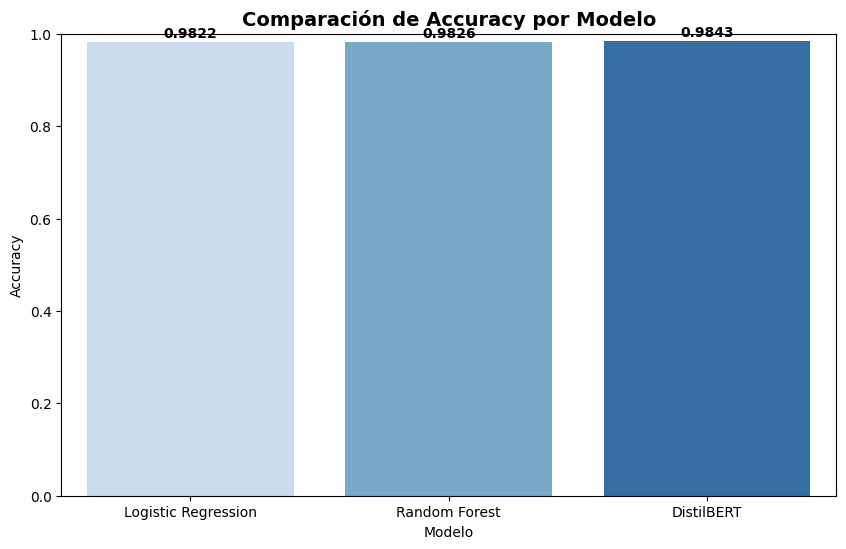

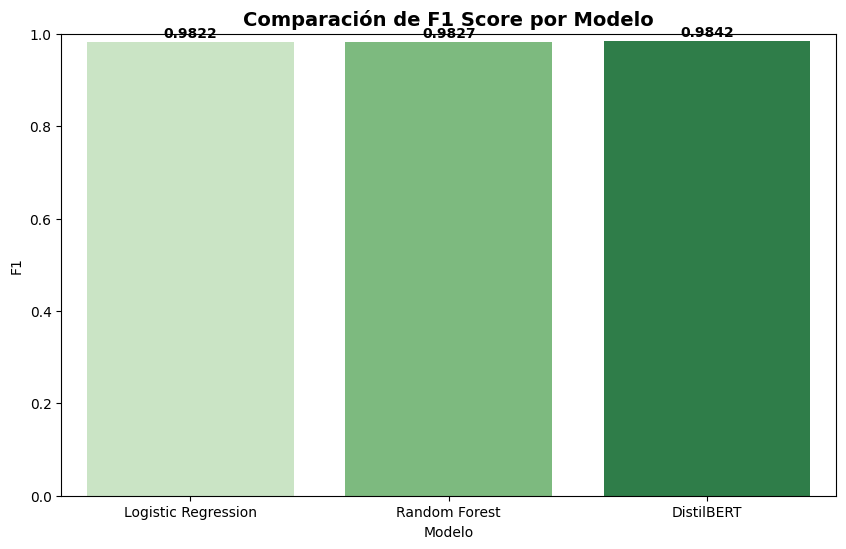

In [23]:
# ==============================================================================
# BLOQUE 17 - COMPARACION FINAL DE MODELOS
# ==============================================================================

resultados = pd.DataFrame({

    "Modelo":[
        "Logistic Regression",
        "Random Forest",
        "DistilBERT"
    ],

    "Accuracy":[
        acc_lr,
        acc_rf,
        acc_bert
    ],

    "Precision":[
        prec_lr,
        prec_rf,
        prec_bert
    ],

    "Recall":[
        rec_lr,
        rec_rf,
        rec_bert
    ],

    "F1":[
        f1_lr,
        f1_rf,
        f1_bert
    ]
})

print("📊 RESULTADOS FINALES")

display(
    resultados.sort_values(
        by="F1",
        ascending=False
    )
)

# ==============================================================================
# GRAFICO ACCURACY
# ==============================================================================

plt.figure(figsize=(10,6))

sns.barplot(
    data=resultados,
    x="Modelo",
    y="Accuracy",
    palette="Blues"
)

plt.title(
    "Comparación de Accuracy por Modelo",
    fontsize=14,
    fontweight="bold"
)

plt.ylim(0,1)

for i,v in enumerate(resultados["Accuracy"]):

    plt.text(
        i,
        v + 0.01,
        f"{v:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.show()


# ==============================================================================
# GRAFICO F1 SCORE
# ==============================================================================

plt.figure(figsize=(10,6))

sns.barplot(
    data=resultados,
    x="Modelo",
    y="F1",
    palette="Greens"
)

plt.title(
    "Comparación de F1 Score por Modelo",
    fontsize=14,
    fontweight="bold"
)

plt.ylim(0,1)

for i,v in enumerate(resultados["F1"]):

    plt.text(
        i,
        v + 0.01,
        f"{v:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.show()

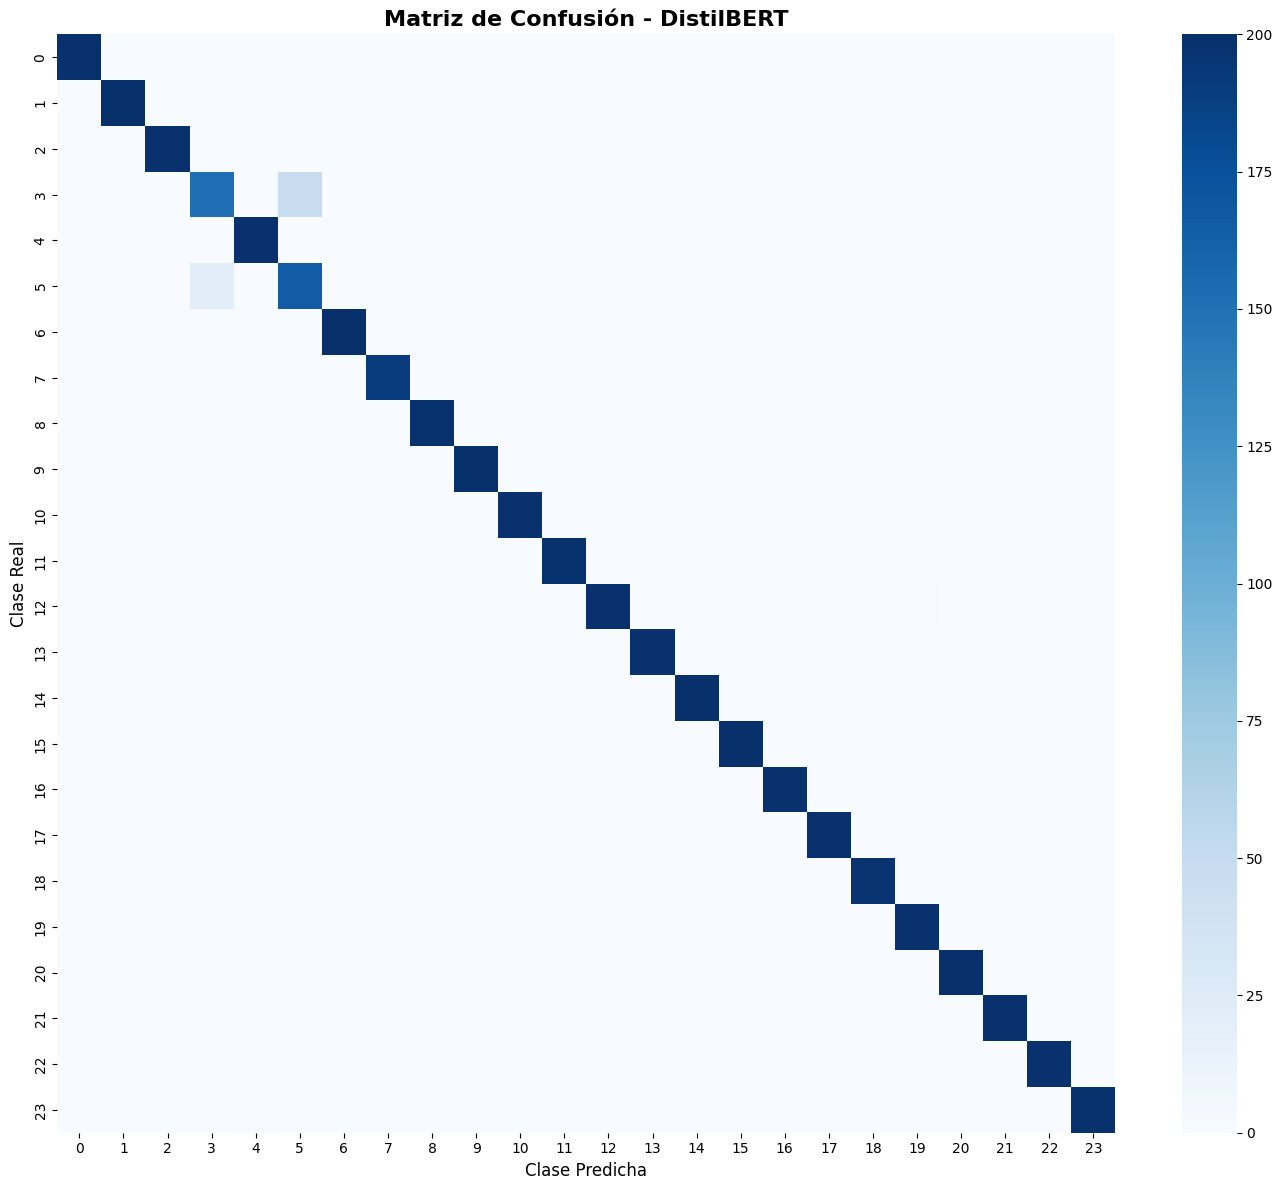

In [24]:
# ==============================================================================
# BLOQUE 18 - MATRIZ DE CONFUSION DISTILBERT
# ==============================================================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    pred_distilbert
)

plt.figure(figsize=(14,12))

sns.heatmap(
    cm,
    cmap="Blues",
    cbar=True
)

plt.title(
    "Matriz de Confusión - DistilBERT",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Clase Predicha",
    fontsize=12
)

plt.ylabel(
    "Clase Real",
    fontsize=12
)

plt.tight_layout()

plt.show()
